EDA, evaluation, visualizations

In [42]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Загружаем датасет
df = pd.read_csv("../data/StudentsPerformance.csv")

# Показываем первые 5 строк
display(df.head())

,gender,race/ethnicity,parental level of education,lunch,test preparation course,math score,reading score,writing score
0,female,group B,bachelor's degree,standard,none,72,72,74
1,female,group C,some college,standard,completed,69,90,88
2,female,group B,master's degree,standard,none,90,95,93
3,male,group A,associate's degree,free/reduced,none,47,57,44
4,male,group C,some college,standard,none,76,78,75


In [43]:
# Размер таблицы
print("Размер датасета:", df.shape)

# Названия колонок
print("\nКолонки:")
print(df.columns.tolist())

# Типы данных и пропущенные значения
print("\nИнформация о данных:")
df.info()

# Количество пропущенных значений
print("\nПропущенные значения:")
print(df.isnull().sum())

Размер датасета: (1000, 8)

Колонки:
['gender', 'race/ethnicity', 'parental level of education', 'lunch', 'test preparation course', 'math score', 'reading score', 'writing score']

Информация о данных:
<class 'pandas.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 8 columns):
 #   Column                       Non-Null Count  Dtype
---  ------                       --------------  -----
 0   gender                       1000 non-null   str  
 1   race/ethnicity               1000 non-null   str  
 2   parental level of education  1000 non-null   str  
 3   lunch                        1000 non-null   str  
 4   test preparation course      1000 non-null   str  
 5   math score                   1000 non-null   int64
 6   reading score                1000 non-null   int64
 7   writing score                1000 non-null   int64
dtypes: int64(3), str(5)
memory usage: 62.6 KB

Пропущенные значения:
gender                         0
race/ethnicity                 0
parenta

In [44]:
# Считаем средний балл по трём экзаменам
df["average_score"] = (
    df["math score"]
    + df["reading score"]
    + df["writing score"]
) / 3

# Pass = 1, если средний балл строго больше 60
# Fail = 0, если средний балл меньше или равен 60
df["final_grade"] = (
    df["average_score"] > 60
).astype(int)

# Посмотрим результат
display(
    df[
        [
            "math score",
            "reading score",
            "writing score",
            "average_score",
            "final_grade"
        ]
    ].head(10)
)

,math score,reading score,writing score,average_score,final_grade
0,72,72,74,72.666667,1
1,69,90,88,82.333333,1
2,90,95,93,92.666667,1
3,47,57,44,49.333333,0
4,76,78,75,76.333333,1
5,71,83,78,77.333333,1
6,88,95,92,91.666667,1
7,40,43,39,40.666667,0
8,64,64,67,65.000000,1
9,38,60,50,49.333333,0


final_grade
0    293
1    707
Name: count, dtype: int64
final_grade
0    29.3
1    70.7
Name: proportion, dtype: float64


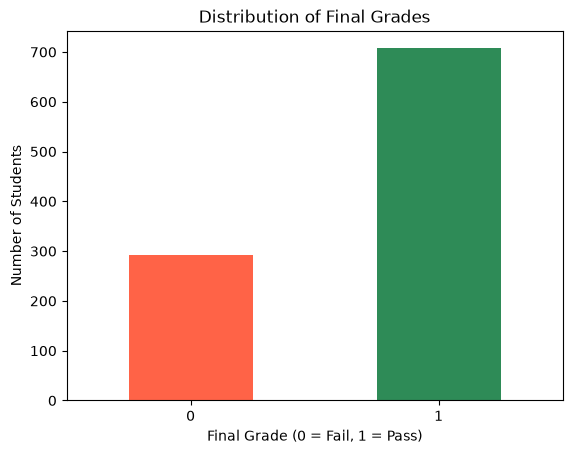

In [45]:
# Количество студентов в каждом классе
print(df["final_grade"].value_counts().sort_index())

# Доли классов в процентах
print(
    df["final_grade"]
    .value_counts(normalize=True)
    .sort_index()
    .mul(100)
)

# Строим график
df["final_grade"].value_counts().sort_index().plot(
    kind="bar",
    color=["tomato", "seagreen"]
)

plt.title("Distribution of Final Grades")
plt.xlabel("Final Grade (0 = Fail, 1 = Pass)")
plt.ylabel("Number of Students")
plt.xticks(rotation=0)
plt.show()

In [46]:
# Признаки, по которым будет работать модель
X = df[
    [
        "gender",
        "race/ethnicity",
        "parental level of education",
        "lunch",
        "test preparation course"
    ]
].copy()

# Правильные ответы, которые модель должна научиться предсказывать
y = df["final_grade"].copy()

print("Размер X:", X.shape)
print("Размер y:", y.shape)

display(X.head())
print(y.head())

Размер X: (1000, 5)
Размер y: (1000,)


,gender,race/ethnicity,parental level of education,lunch,test preparation course
0,female,group B,bachelor's degree,standard,none
1,female,group C,some college,standard,completed
2,female,group B,master's degree,standard,none
3,male,group A,associate's degree,free/reduced,none
4,male,group C,some college,standard,none


0    1
1    1
2    1
3    0
4    1
Name: final_grade, dtype: int64


In [47]:
# Разделяем данные на train и test
# Реализуем разделение самостоятельно, без scikit-learn

rng = np.random.default_rng(42)

indices = rng.permutation(len(X))
split_index = int(len(X) * 0.8)

train_indices = indices[:split_index]
test_indices = indices[split_index:]

X_train = X.iloc[train_indices].copy()
X_test = X.iloc[test_indices].copy()

y_train = y.iloc[train_indices].copy()
y_test = y.iloc[test_indices].copy()

print("Train:", X_train.shape, y_train.shape)
print("Test:", X_test.shape, y_test.shape)

Train: (800, 5) (800,)
Test: (200, 5) (200,)


In [48]:
# Создаём словари категорий только по обучающей выборке
encoders = {}

for column in X_train.columns:
    categories = sorted(X_train[column].dropna().unique())
    encoders[column] = {
        category: code
        for code, category in enumerate(categories)
    }

    # Применяем словарь к train и test
    X_train[column] = X_train[column].map(encoders[column])
    X_test[column] = X_test[column].map(encoders[column])

print("Закодированные данные:")
display(X_train.head())

print("\nСловари кодирования:")
print(encoders)

Закодированные данные:


,gender,race/ethnicity,parental level of education,lunch,test preparation course
978,1,3,2,1,0
933,1,2,1,0,0
859,1,2,0,0,1
916,1,4,1,1,0
127,1,3,4,1,0



Словари кодирования:
{'gender': {'female': 0, 'male': 1}, 'race/ethnicity': {'group A': 0, 'group B': 1, 'group C': 2, 'group D': 3, 'group E': 4}, 'parental level of education': {"associate's degree": 0, "bachelor's degree": 1, 'high school': 2, "master's degree": 3, 'some college': 4, 'some high school': 5}, 'lunch': {'free/reduced': 0, 'standard': 1}, 'test preparation course': {'completed': 0, 'none': 1}}


In [49]:
print("Количество строк в обучении:", len(X_train))
print("Количество строк в тесте:", len(X_test))

print("\nКлассы в обучающей выборке:")
print(y_train.value_counts().sort_index())

print("\nКлассы в тестовой выборке:")
print(y_test.value_counts().sort_index())

print("\nПропуски в X_train:")
print(X_train.isnull().sum())

print("\nПропуски в X_test:")
print(X_test.isnull().sum())

Количество строк в обучении: 800
Количество строк в тесте: 200

Классы в обучающей выборке:
final_grade
0    235
1    565
Name: count, dtype: int64

Классы в тестовой выборке:
final_grade
0     58
1    142
Name: count, dtype: int64

Пропуски в X_train:
gender                         0
race/ethnicity                 0
parental level of education    0
lunch                          0
test preparation course        0
dtype: int64

Пропуски в X_test:
gender                         0
race/ethnicity                 0
parental level of education    0
lunch                          0
test preparation course        0
dtype: int64


In [50]:
import sys
from pathlib import Path

# Добавляем корень проекта в путь поиска модулей
project_root = Path.cwd().parent
if str(project_root) not in sys.path:
    sys.path.insert(0, str(project_root))

from utils.metrics import entropy, gini, information_gain

# Три тестовых группы
pure = np.array([1, 1, 1, 1])
balanced = np.array([0, 0, 1, 1])
mixed = np.array([0, 0, 0, 1])

print("Энтропия чистой группы:", entropy(pure))
print("Энтропия сбалансированной группы:", entropy(balanced))
print("Энтропия смешанной группы:", entropy(mixed))

print("\nGini чистой группы:", gini(pure))
print("Gini сбалансированной группы:", gini(balanced))

print("\nInformation Gain:")
print(
    information_gain(
        np.array([0, 0, 1, 1]),
        np.array([0, 0]),
        np.array([1, 1])
    )
)

Энтропия чистой группы: 0.0
Энтропия сбалансированной группы: 1.0
Энтропия смешанной группы: 0.8112781244591328

Gini чистой группы: 0.0
Gini сбалансированной группы: 0.5

Information Gain:
1.0


In [51]:
print("Размер обучающей выборки:", X_train.shape)
print("Размер тестовой выборки:", X_test.shape)
print("Признаки:", X_train.columns.tolist())

Размер обучающей выборки: (800, 5)
Размер тестовой выборки: (200, 5)
Признаки: ['gender', 'race/ethnicity', 'parental level of education', 'lunch', 'test preparation course']


In [52]:
from model.decision_tree import DecisionTree

tree = DecisionTree(
    max_depth=5,
    min_samples_split=2
)

tree.fit(X_train.values, y_train.values)

print("Модель успешно обучена!")

Модель успешно обучена!


In [53]:
y_pred = tree.predict(X_test.values)

comparison = pd.DataFrame({
    "Actual": y_test.values,
    "Predicted": y_pred
})

display(comparison.head(10))

,Actual,Predicted
0,1,1
1,0,1
2,1,1
3,0,0
4,0,1
5,1,1
6,0,1
7,1,1
8,1,1
9,1,1


In [54]:
import numpy as np

# Сравниваем предсказания с настоящими результатами
correct_predictions = np.sum(y_pred == y_test.values)

# Количество всех предсказаний
total_predictions = len(y_test)

# Вычисляем точность
accuracy = correct_predictions / total_predictions

print(f"Правильных предсказаний: {correct_predictions}")
print(f"Всего студентов: {total_predictions}")
print(f"Accuracy: {accuracy:.2%}")

Правильных предсказаний: 135
Всего студентов: 200
Accuracy: 67.50%


In [55]:
# Находим самый частый класс в обучающих данных
majority_class = y_train.mode()[0]

# Всегда предсказываем этот класс
baseline_pred = np.full(len(y_test), majority_class)

# Вычисляем точность baseline
baseline_accuracy = np.mean(
    baseline_pred == y_test.values
)

print(f"Decision Tree Accuracy: {accuracy:.2%}")
print(f"Baseline Accuracy: {baseline_accuracy:.2%}")

Decision Tree Accuracy: 67.50%
Baseline Accuracy: 71.00%


In [56]:
# Добавляем оценки по трём предметам
score_columns = [
    "math score",
    "reading score",
    "writing score"
]

# Создаём новые наборы признаков
X_train_full = X_train.copy()
X_test_full = X_test.copy()

# Берём оценки из исходного датафрейма по индексам
for column in score_columns:
    X_train_full[column] = df.loc[X_train.index, column]
    X_test_full[column] = df.loc[X_test.index, column]

print("Количество признаков:", X_train_full.shape[1])
print("Обучающая выборка:", X_train_full.shape)
print("Тестовая выборка:", X_test_full.shape)

display(X_train_full.head())

Количество признаков: 8
Обучающая выборка: (800, 8)
Тестовая выборка: (200, 8)


,gender,race/ethnicity,parental level of education,lunch,test preparation course,math score,reading score,writing score
978,1,3,2,1,0,55,41,48
933,1,2,1,0,0,70,75,74
859,1,2,0,0,1,87,73,72
916,1,4,1,1,0,100,100,100
127,1,3,4,1,0,65,77,74


In [57]:
# Создаём вторую модель с 8 признаками
tree_full = DecisionTree(
    max_depth=5,
    min_samples_split=2
)

# Обучаем модель
tree_full.fit(
    X_train_full.values,
    y_train.values
)

# Получаем предсказания
y_pred_full = tree_full.predict(X_test_full.values)

# Рассчитываем точность
accuracy_full = np.mean(y_pred_full == y_test.values)

print(f"Decision Tree (5 признаков): {accuracy:.2%}")
print(f"Decision Tree (8 признаков): {accuracy_full:.2%}")
print(f"Dummy Baseline: {baseline_accuracy:.2%}")

Decision Tree (5 признаков): 67.50%
Decision Tree (8 признаков): 97.50%
Dummy Baseline: 71.00%


In [58]:
import numpy as np
import pandas as pd

# Настоящие результаты и прогнозы
y_true = y_test.values
y_predicted = np.array(y_pred_full)

# Вычисляем четыре типа результатов
tn = np.sum((y_true == 0) & (y_predicted == 0))
fp = np.sum((y_true == 0) & (y_predicted == 1))
fn = np.sum((y_true == 1) & (y_predicted == 0))
tp = np.sum((y_true == 1) & (y_predicted == 1))

# Создаём Confusion Matrix
confusion_matrix = pd.DataFrame(
    [[tn, fp], [fn, tp]],
    index=["Actual Fail (0)", "Actual Pass (1)"],
    columns=["Predicted Fail (0)", "Predicted Pass (1)"]
)

display(confusion_matrix)

print("True Negative:", tn)
print("False Positive:", fp)
print("False Negative:", fn)
print("True Positive:", tp)
print("Всего ошибок:", fp + fn)

,Predicted Fail (0),Predicted Pass (1)
Actual Fail (0),56,2
Actual Pass (1),3,139


True Negative: 56
False Positive: 2
False Negative: 3
True Positive: 139
Всего ошибок: 5


In [59]:
# Названия восьми признаков
feature_names = X_train_full.columns.tolist()

# Выводим дерево решений
tree_full.print_tree(feature_names=feature_names)

if reading score <= 61.500:
  if math score <= 60.500:
    if writing score <= 65.500:
      Predict class = 0
    else:
      if test preparation course <= 0.500:
        Predict class = 0
      else:
        Predict class = 1
  else:
    if writing score <= 57.500:
      if math score <= 67.500:
        Predict class = 0
      else:
        if reading score <= 57.000:
          Predict class = 0
        else:
          Predict class = 1
    else:
      Predict class = 1
else:
  if math score <= 53.500:
    if reading score <= 66.500:
      if writing score <= 67.500:
        Predict class = 0
      else:
        if race/ethnicity <= 1.500:
          Predict class = 1
        else:
          Predict class = 0
    else:
      Predict class = 1
  else:
    if reading score <= 62.500:
      if math score <= 58.500:
        Predict class = 0
      else:
        Predict class = 1
    else:
      Predict class = 1


In [60]:
# Проверяем структуру обученного дерева
print("Атрибуты модели:")
print(vars(tree_full))

print("\nАтрибуты корневого узла:")
print(vars(tree_full.root))

Атрибуты модели:
{'max_depth': 5, 'min_samples_split': 2, 'root': Node(prediction=1, feature_index=6, threshold=61.5, left=Node(prediction=0, feature_index=5, threshold=60.5, left=Node(prediction=0, feature_index=7, threshold=65.5, left=Node(prediction=0, feature_index=None, threshold=None, left=None, right=None), right=Node(prediction=0, feature_index=4, threshold=0.5, left=Node(prediction=0, feature_index=None, threshold=None, left=None, right=None), right=Node(prediction=1, feature_index=None, threshold=None, left=None, right=None))), right=Node(prediction=0, feature_index=7, threshold=57.5, left=Node(prediction=0, feature_index=5, threshold=67.5, left=Node(prediction=0, feature_index=None, threshold=None, left=None, right=None), right=Node(prediction=0, feature_index=6, threshold=57.0, left=Node(prediction=0, feature_index=None, threshold=None, left=None, right=None), right=Node(prediction=1, feature_index=None, threshold=None, left=None, right=None))), right=Node(prediction=1, fea

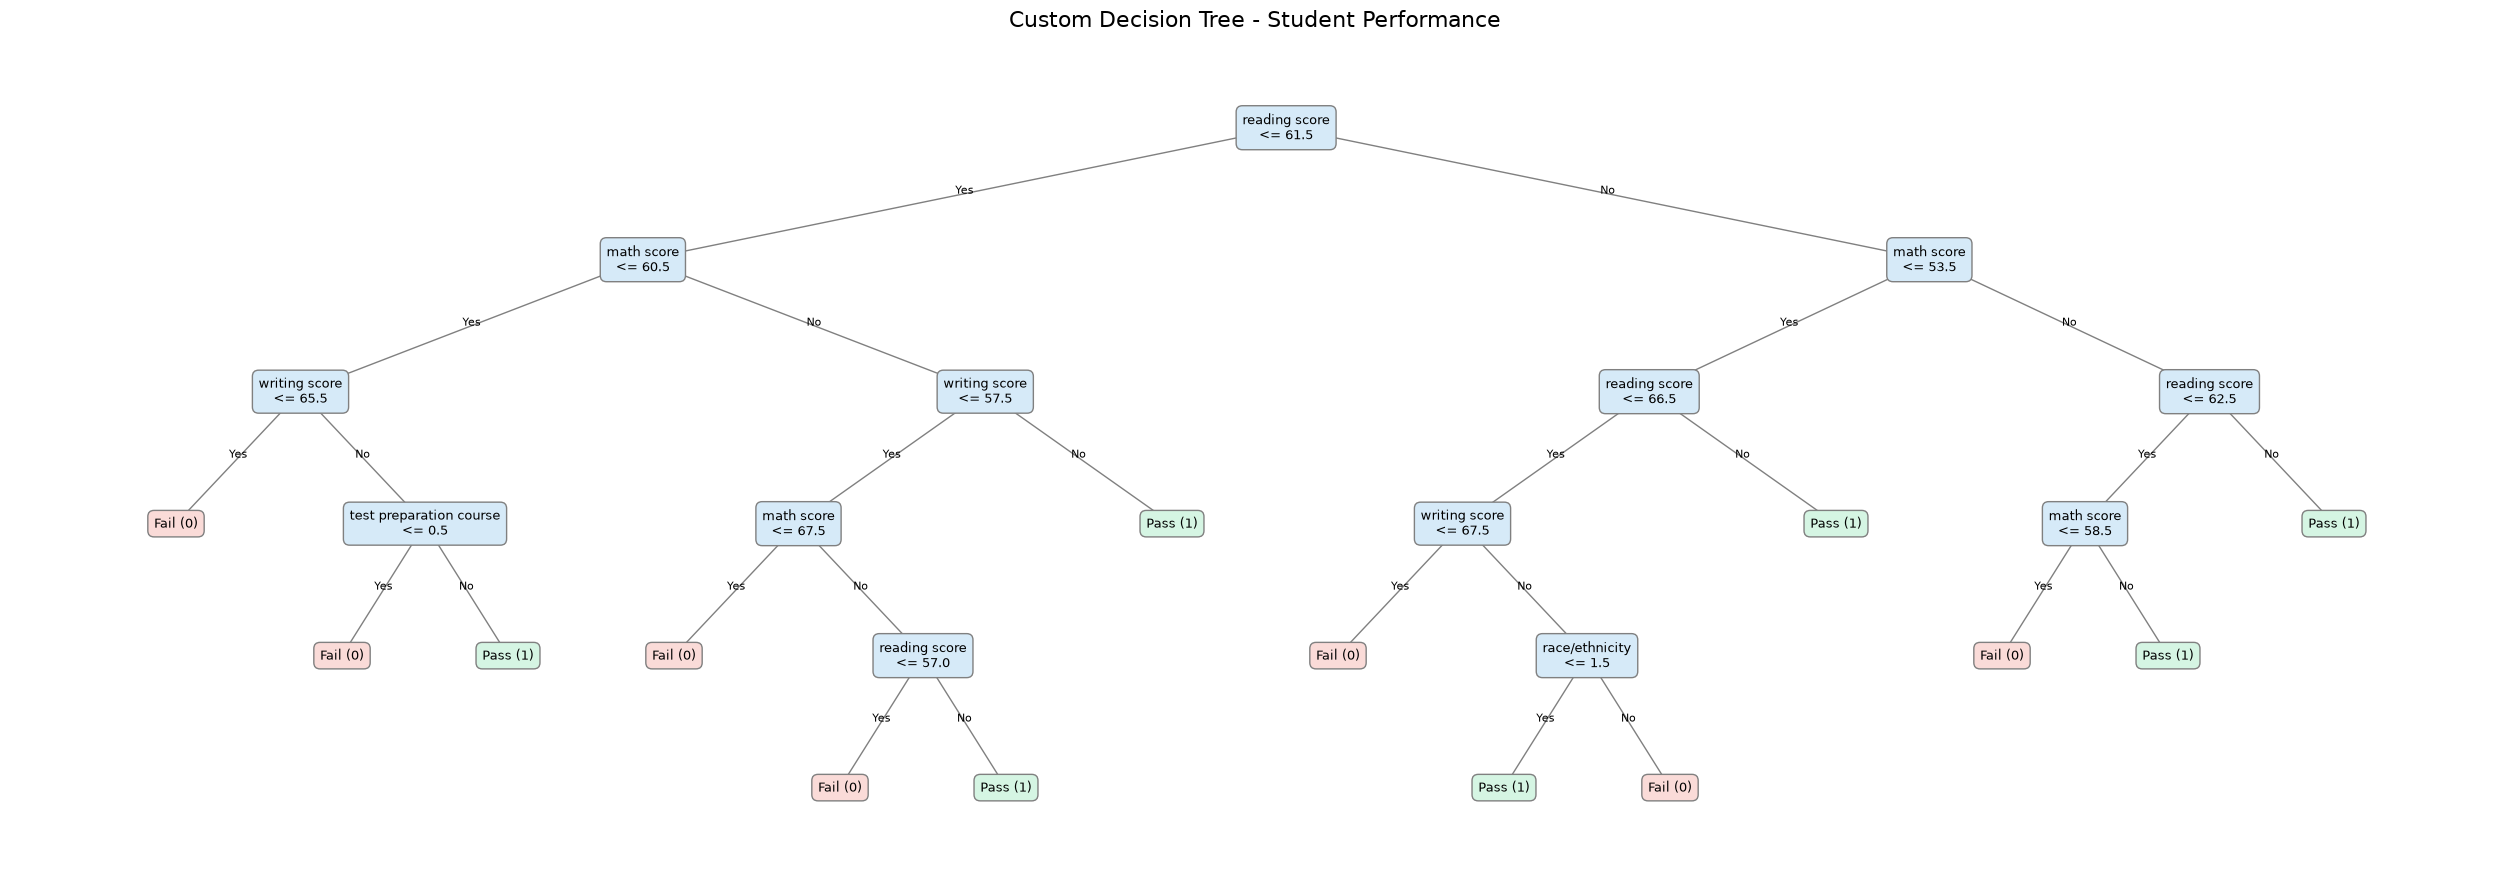

Дерево сохранено: /Users/Guest/edu-predict/results/tree_visualization.png
Количество листьев: 14
Глубина дерева: 5


In [61]:
import matplotlib.pyplot as plt
from pathlib import Path

feature_names = X_train_full.columns.tolist()

# Определяем количество конечных узлов
def count_leaves(node):
    if node.feature_index is None:
        return 1

    return count_leaves(node.left) + count_leaves(node.right)


# Определяем глубину дерева
def get_depth(node):
    if node.feature_index is None:
        return 0

    return 1 + max(
        get_depth(node.left),
        get_depth(node.right)
    )


# Вычисляем координаты узлов
positions = {}
labels = {}
leaf_counter = [0]

def calculate_positions(node, depth=0):
    node_id = id(node)

    if node.feature_index is None:
        x = leaf_counter[0]
        leaf_counter[0] += 1
        label = "Pass (1)" if node.prediction == 1 else "Fail (0)"
    else:
        left_x = calculate_positions(node.left, depth + 1)
        right_x = calculate_positions(node.right, depth + 1)

        x = (left_x + right_x) / 2

        feature = feature_names[node.feature_index]
        label = f"{feature}\n<= {node.threshold:.1f}"

    positions[node_id] = (x, -depth)
    labels[node_id] = label

    return x


calculate_positions(tree_full.root)

# Создаём изображение
fig, ax = plt.subplots(
    figsize=(max(16, count_leaves(tree_full.root) * 1.8), 9)
)

def draw_tree(node):
    x, y = positions[id(node)]

    if node.feature_index is None:
        color = "#D5F5E3" if node.prediction == 1 else "#FADBD8"
    else:
        color = "#D6EAF8"

    ax.text(
        x, y, labels[id(node)],
        ha="center",
        va="center",
        fontsize=9,
        bbox=dict(
            boxstyle="round,pad=0.5",
            facecolor=color,
            edgecolor="gray"
        )
    )

    if node.feature_index is not None:
        for child, edge_label in [
            (node.left, "Yes"),
            (node.right, "No")
        ]:
            child_x, child_y = positions[id(child)]

            ax.plot(
                [x, child_x],
                [y, child_y],
                color="gray",
                linewidth=1
            )

            ax.text(
                (x + child_x) / 2,
                (y + child_y) / 2,
                edge_label,
                fontsize=8,
                ha="center"
            )

            draw_tree(child)


draw_tree(tree_full.root)

ax.set_xlim(-1, count_leaves(tree_full.root))
ax.set_ylim(-get_depth(tree_full.root) - 0.7, 0.7)
ax.axis("off")

plt.title("Custom Decision Tree - Student Performance", fontsize=16)
plt.tight_layout()

# Сохраняем изображение в results/
project_root = Path.cwd()

if project_root.name == "notebook":
    project_root = project_root.parent

results_dir = project_root / "results"
results_dir.mkdir(exist_ok=True)

output_path = results_dir / "tree_visualization.png"

plt.savefig(output_path, dpi=200, bbox_inches="tight")
plt.show()

print(f"Дерево сохранено: {output_path}")
print(f"Количество листьев: {count_leaves(tree_full.root)}")
print(f"Глубина дерева: {get_depth(tree_full.root)}")

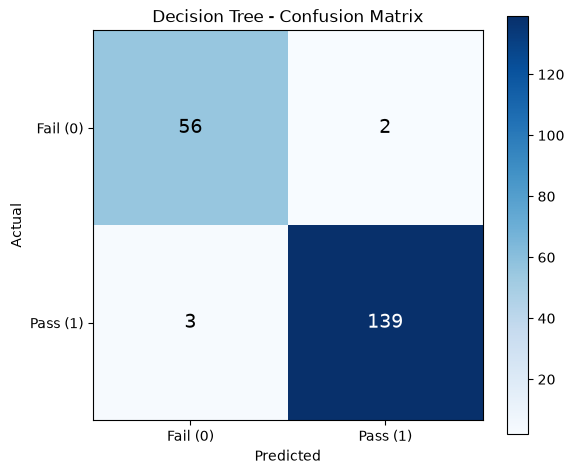

Saved: /Users/Guest/edu-predict/results/confusion_matrix.png


In [62]:

import matplotlib.pyplot as plt
import numpy as np
from pathlib import Path

cm = np.array([[tn, fp], [fn, tp]])

fig, ax = plt.subplots(figsize=(6, 5))
image = ax.imshow(cm, cmap="Blues")

ax.set_xticks([0, 1])
ax.set_yticks([0, 1])
ax.set_xticklabels(["Fail (0)", "Pass (1)"])
ax.set_yticklabels(["Fail (0)", "Pass (1)"])

ax.set_xlabel("Predicted")
ax.set_ylabel("Actual")
ax.set_title("Decision Tree - Confusion Matrix")

for i in range(2):
    for j in range(2):
        ax.text(
            j, i, str(cm[i, j]),
            ha="center",
            va="center",
            fontsize=14,
            color="white" if cm[i, j] > cm.max() / 2 else "black"
        )

fig.colorbar(image, ax=ax)

project_root = Path.cwd()
if project_root.name == "notebook":
    project_root = project_root.parent

output_path = project_root / "results" / "confusion_matrix.png"
output_path.parent.mkdir(parents=True, exist_ok=True)

plt.tight_layout()
plt.savefig(output_path, dpi=200, bbox_inches="tight")
plt.show()

print(f"Saved: {output_path}")


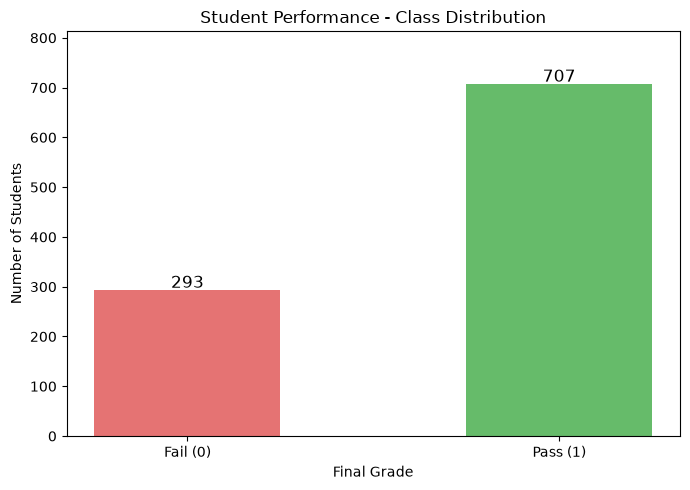

Saved: /Users/Guest/edu-predict/results/class_distribution.png
Fail (0): 293
Pass (1): 707


In [63]:

import matplotlib.pyplot as plt
from pathlib import Path

# Подсчитываем студентов каждого класса
class_counts = df["final_grade"].value_counts().reindex(
    [0, 1], fill_value=0
)

# Создаём график
fig, ax = plt.subplots(figsize=(7, 5))

bars = ax.bar(
    ["Fail (0)", "Pass (1)"],
    class_counts.values,
    color=["#E57373", "#66BB6A"],
    width=0.5
)

# Показываем количество над столбцами
for bar in bars:
    height = bar.get_height()
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        height + 5,
        str(int(height)),
        ha="center",
        fontsize=12
    )

ax.set_title("Student Performance - Class Distribution")
ax.set_xlabel("Final Grade")
ax.set_ylabel("Number of Students")
ax.set_ylim(0, max(class_counts.values) * 1.15)

plt.tight_layout()

# Сохраняем изображение
project_root = Path.cwd()

if project_root.name == "notebook":
    project_root = project_root.parent

output_path = project_root / "results" / "class_distribution.png"
output_path.parent.mkdir(parents=True, exist_ok=True)

plt.savefig(output_path, dpi=200, bbox_inches="tight")
plt.show()

print(f"Saved: {output_path}")
print(f"Fail (0): {class_counts[0]}")
print(f"Pass (1): {class_counts[1]}")


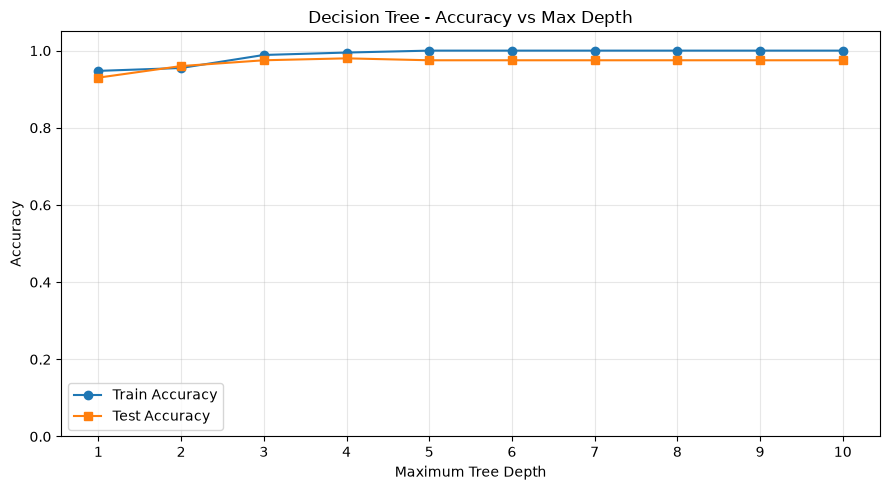

Depth 1: Train = 94.75%, Test = 93.00%
Depth 2: Train = 95.50%, Test = 96.00%
Depth 3: Train = 98.88%, Test = 97.50%
Depth 4: Train = 99.50%, Test = 98.00%
Depth 5: Train = 100.00%, Test = 97.50%
Depth 6: Train = 100.00%, Test = 97.50%
Depth 7: Train = 100.00%, Test = 97.50%
Depth 8: Train = 100.00%, Test = 97.50%
Depth 9: Train = 100.00%, Test = 97.50%
Depth 10: Train = 100.00%, Test = 97.50%

Best test accuracy: 98.00% at depth 4


In [64]:

import matplotlib.pyplot as plt
import numpy as np
from pathlib import Path

depths = range(1, 11)

train_accuracies = []
test_accuracies = []

for depth in depths:
    # Создаём отдельную модель для каждой глубины
    model = DecisionTree(
        max_depth=depth,
        min_samples_split=2
    )

    # Обучаем
    model.fit(X_train_full.values, y_train.values)

    # Делаем предсказания
    train_pred = model.predict(X_train_full.values)
    test_pred = model.predict(X_test_full.values)

    # Считаем точность
    train_acc = np.mean(train_pred == y_train.values)
    test_acc = np.mean(test_pred == y_test.values)

    train_accuracies.append(train_acc)
    test_accuracies.append(test_acc)

# Строим график
fig, ax = plt.subplots(figsize=(9, 5))

ax.plot(
    list(depths),
    train_accuracies,
    marker="o",
    label="Train Accuracy"
)

ax.plot(
    list(depths),
    test_accuracies,
    marker="s",
    label="Test Accuracy"
)

ax.set_title("Decision Tree - Accuracy vs Max Depth")
ax.set_xlabel("Maximum Tree Depth")
ax.set_ylabel("Accuracy")
ax.set_xticks(list(depths))
ax.set_ylim(0, 1.05)
ax.grid(True, alpha=0.3)
ax.legend()

plt.tight_layout()

# Сохраняем
project_root = Path.cwd()

if project_root.name == "notebook":
    project_root = project_root.parent

output_path = project_root / "results" / "depth_comparison.png"
output_path.parent.mkdir(parents=True, exist_ok=True)

plt.savefig(output_path, dpi=200, bbox_inches="tight")
plt.show()

# Выводим значения
for depth, train_acc, test_acc in zip(
    depths, train_accuracies, test_accuracies
):
    print(
        f"Depth {depth}: "
        f"Train = {train_acc:.2%}, "
        f"Test = {test_acc:.2%}"
    )

best_index = int(np.argmax(test_accuracies))

print(
    f"\nBest test accuracy: "
    f"{test_accuracies[best_index]:.2%} "
    f"at depth {list(depths)[best_index]}"
)


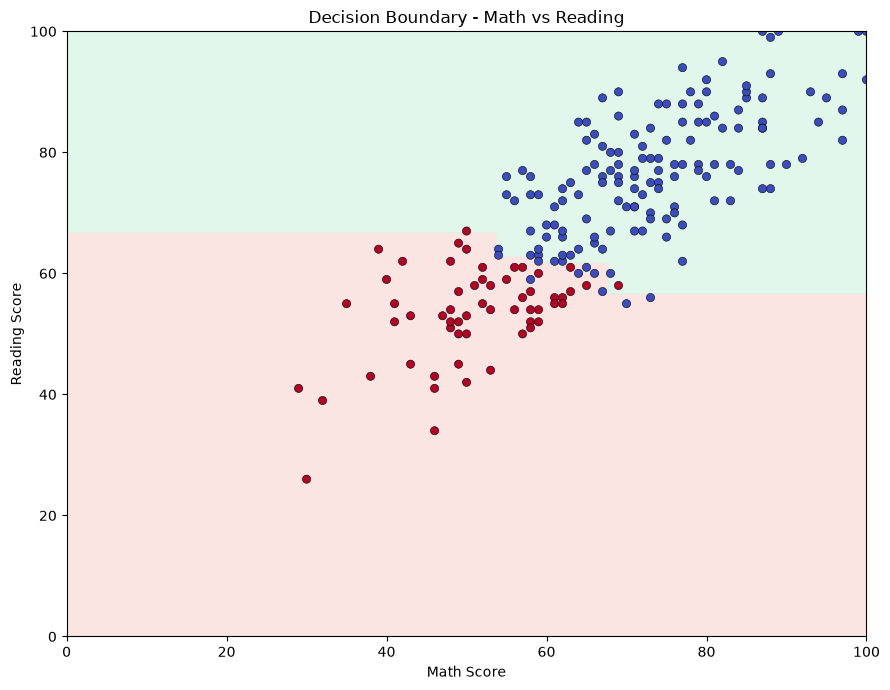

2D Decision Tree Accuracy: 95.50%
Saved: /Users/Guest/edu-predict/results/decision_boundary_2d.png


In [65]:

import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

# Два признака для визуализации
features_2d = ["math score", "reading score"]

X_train_2d = X_train_full[features_2d].values
X_test_2d = X_test_full[features_2d].values

# Обучаем отдельное дерево
tree_2d = DecisionTree(
    max_depth=4,
    min_samples_split=2
)

tree_2d.fit(X_train_2d, y_train.values)

# Формируем сетку координат
xx, yy = np.meshgrid(
    np.linspace(0, 100, 201),
    np.linspace(0, 100, 201)
)

grid_points = np.c_[xx.ravel(), yy.ravel()]

# Получаем прогноз для каждой точки
Z = np.array(tree_2d.predict(grid_points))
Z = Z.reshape(xx.shape)

# Строим график
fig, ax = plt.subplots(figsize=(9, 7))

ax.contourf(
    xx, yy, Z,
    levels=[-0.5, 0.5, 1.5],
    colors=["#FADBD8", "#D5F5E3"],
    alpha=0.7
)

scatter = ax.scatter(
    X_test_2d[:, 0],
    X_test_2d[:, 1],
    c=y_test.values,
    cmap="coolwarm_r",
    edgecolors="black",
    linewidths=0.4,
    s=35
)

ax.set_xlabel("Math Score")
ax.set_ylabel("Reading Score")
ax.set_title("Decision Boundary - Math vs Reading")
ax.set_xlim(0, 100)
ax.set_ylim(0, 100)

plt.tight_layout()

# Сохраняем изображение
project_root = Path.cwd()
if project_root.name == "notebook":
    project_root = project_root.parent

output_path = project_root / "results" / "decision_boundary_2d.png"
output_path.parent.mkdir(parents=True, exist_ok=True)

plt.savefig(output_path, dpi=200, bbox_inches="tight")
plt.show()

# Точность отдельной 2D-модели
pred_2d = np.array(tree_2d.predict(X_test_2d))
accuracy_2d = np.mean(pred_2d == y_test.values)

print(f"2D Decision Tree Accuracy: {accuracy_2d:.2%}")
print(f"Saved: {output_path}")


In [66]:
import json
from pathlib import Path

metrics = {
    "decision_tree_5_features_accuracy": round(float(accuracy), 4),
    "decision_tree_8_features_accuracy": round(float(accuracy_full), 4),
    "dummy_baseline_accuracy": round(float(baseline_accuracy), 4),
    "best_depth_test_accuracy": 0.98,
    "best_depth": 4,
    "decision_tree_2d_accuracy": round(float(accuracy_2d), 4),
    "confusion_matrix": {
        "true_negative": int(tn),
        "false_positive": int(fp),
        "false_negative": int(fn),
        "true_positive": int(tp)
    },
    "class_distribution": {
        "fail_0": 293,
        "pass_1": 707
    }
}

project_root = Path.cwd()
if project_root.name == "notebook":
    project_root = project_root.parent

output_path = project_root / "results" / "metrics.json"
output_path.parent.mkdir(parents=True, exist_ok=True)

with open(output_path, "w", encoding="utf-8") as f:
    json.dump(metrics, f, indent=4, ensure_ascii=False)

print(f"Saved: {output_path}")

Saved: /Users/Guest/edu-predict/results/metrics.json


In [67]:
from pathlib import Path

feature_names = X_train_full.columns.tolist()

def tree_to_lines(node, feature_names, depth=0):
    lines = []
    indent = "  " * depth

    if node.feature_index is None:
        lines.append(f"{indent}Predict class = {node.prediction}")
        return lines

    feature = feature_names[node.feature_index]
    threshold = node.threshold

    lines.append(f"{indent}if {feature} <= {threshold:.3f}:")
    lines.extend(tree_to_lines(node.left, feature_names, depth + 1))
    lines.append(f"{indent}else:")
    lines.extend(tree_to_lines(node.right, feature_names, depth + 1))

    return lines

tree_lines = tree_to_lines(tree_full.root, feature_names)
tree_text = "\n".join(tree_lines)

project_root = Path.cwd()
if project_root.name == "notebook":
    project_root = project_root.parent

output_path = project_root / "results" / "tree_structure.txt"
output_path.parent.mkdir(parents=True, exist_ok=True)

with open(output_path, "w", encoding="utf-8") as f:
    f.write(tree_text)

print(tree_text[:1000])  # показывает начало дерева
print(f"\nSaved: {output_path}")

if reading score <= 61.500:
  if math score <= 60.500:
    if writing score <= 65.500:
      Predict class = 0
    else:
      if test preparation course <= 0.500:
        Predict class = 0
      else:
        Predict class = 1
  else:
    if writing score <= 57.500:
      if math score <= 67.500:
        Predict class = 0
      else:
        if reading score <= 57.000:
          Predict class = 0
        else:
          Predict class = 1
    else:
      Predict class = 1
else:
  if math score <= 53.500:
    if reading score <= 66.500:
      if writing score <= 67.500:
        Predict class = 0
      else:
        if race/ethnicity <= 1.500:
          Predict class = 1
        else:
          Predict class = 0
    else:
      Predict class = 1
  else:
    if reading score <= 62.500:
      if math score <= 58.500:
        Predict class = 0
      else:
        Predict class = 1
    else:
      Predict class = 1

Saved: /Users/Guest/edu-predict/results/tree_structure.txt
